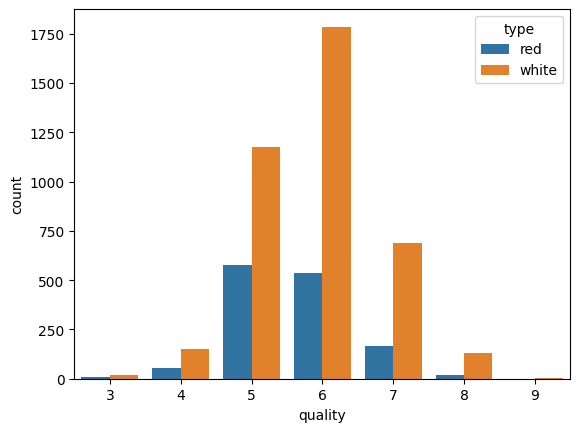

quality
3    0.005642
4    0.038744
5    0.329509
6    0.436336
7    0.160993
8    0.027835
9    0.000940
Name: proportion, dtype: float64


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.countplot(data=df, x="quality", hue="type")
plt.show()

print(df["quality"].value_counts(normalize=True).sort_index())

### Distribuição da variável alvo (`quality`)

**1. As notas se concentram em 5 e 6.**
A nota 6 representa cerca de 43% dos vinhos e a nota 5 cerca de 33%:
juntas, somam aproximadamente 3 em cada 4 amostras. A nota 7 tem
cerca de 16%, e as notas 3, 4, 8 e 9 somadas não chegam a 8%.

**2. Apenas as notas de 3 a 9 aparecem.**
Embora a escala vá de 0 a 10, nenhum vinho recebeu notas extremas
(0, 1, 2 ou 10). A nota 9 tem apenas 5 amostras, todas de vinho branco.

**3. Tintos e brancos têm notas um pouco diferentes.**
No vinho tinto, a nota mais comum é 5; no branco, é 6.

**O que isso significa para os modelos:**
- **Regressão:** com tantas amostras perto de 5 e 6, o modelo tende
  a prever valores nessa região e deve errar mais nos vinhos muito
  bons ou muito ruins.
- **Classificação:** prever a nota exata seria inviável para as notas
  raras (5 amostras de nota 9 não bastam para o modelo aprender).
  Isso justifica agrupar as notas em faixas, como pede o enunciado,
  e avaliar técnicas de balanceamento.
- **Divisão treino/teste:** a separação deve ser estratificada pela
  `quality`, para que as notas raras apareçam nos dois conjuntos.

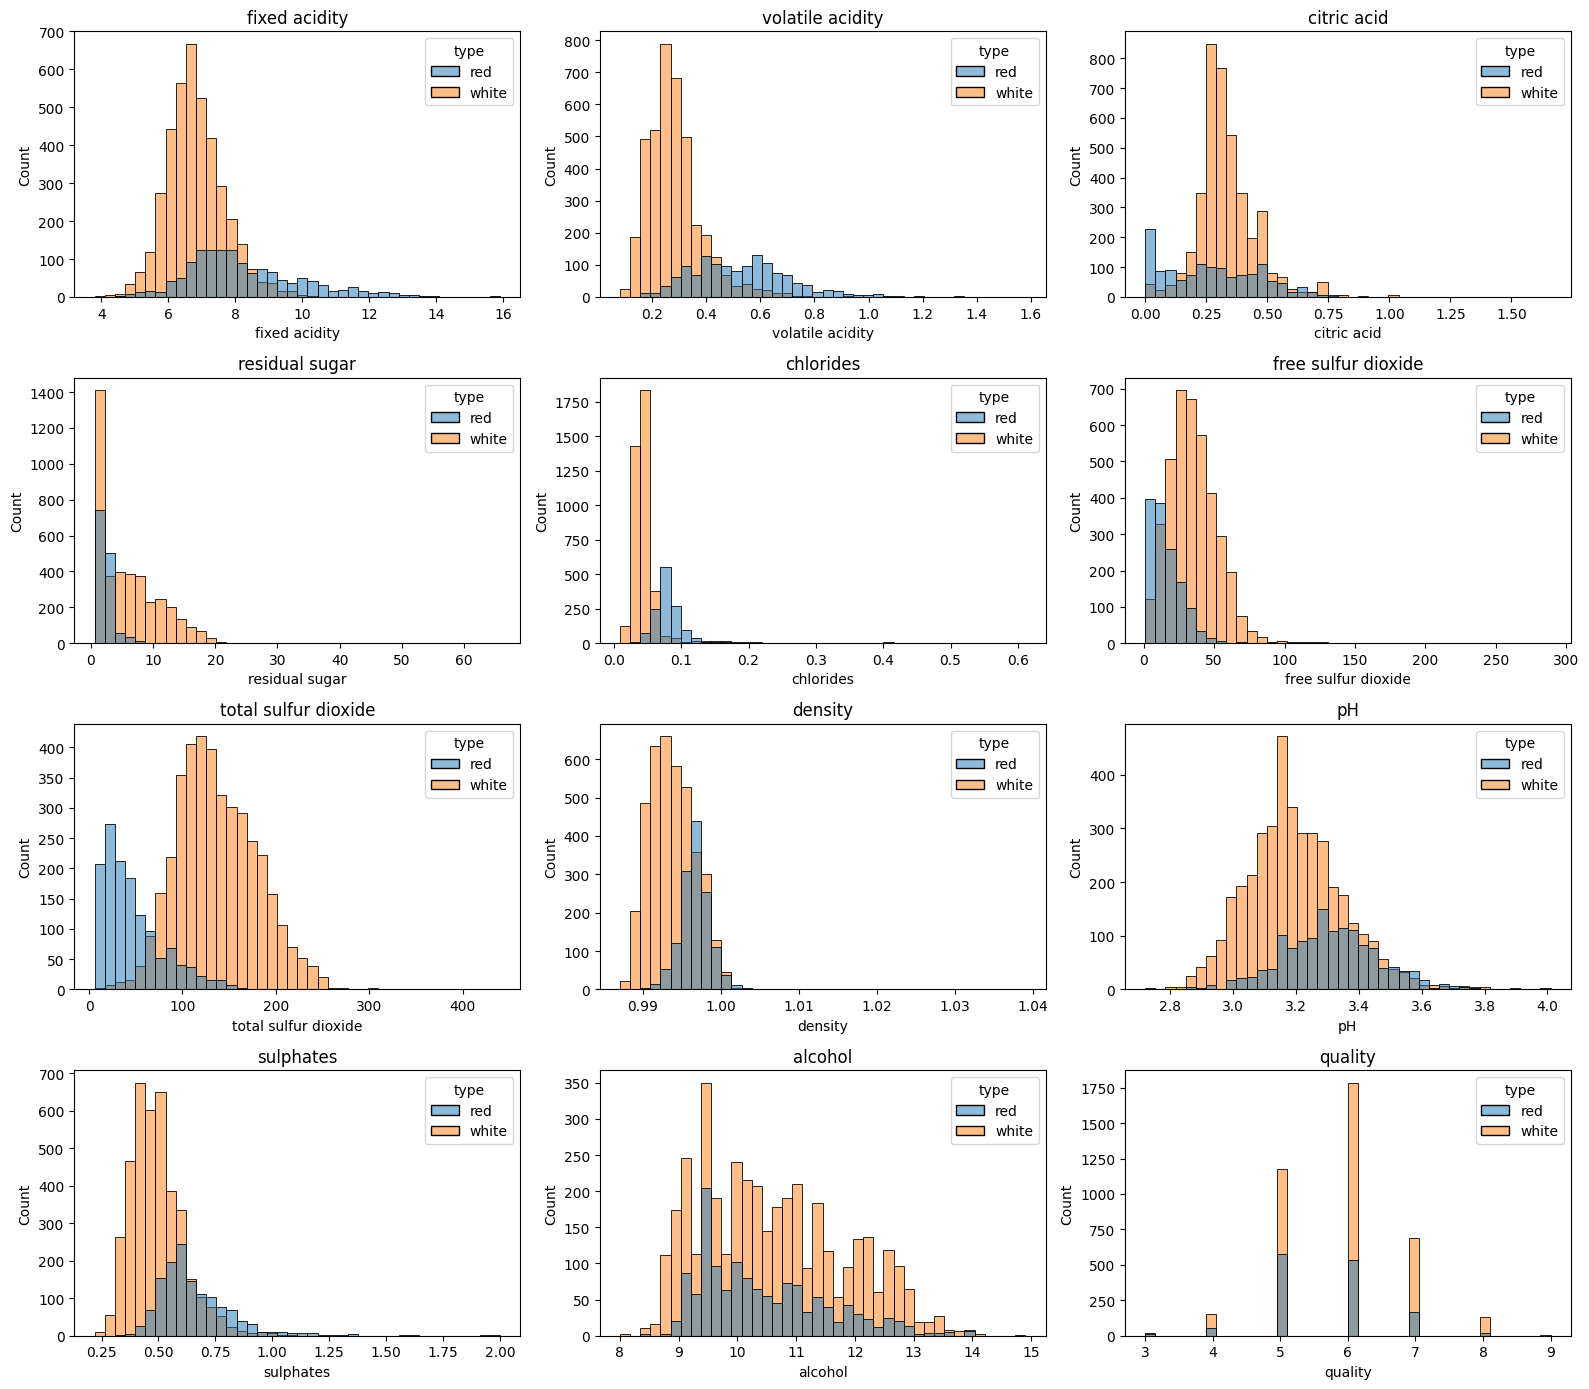

In [12]:
df = pd.read_csv("../data/processed/winequality_clean.csv")

colunas_numericas = df.select_dtypes("number").columns

# Uma grade de 4 linhas x 3 colunas, um gráfico para cada variável
fig, eixos = plt.subplots(4, 3, figsize=(16, 14))

for eixo, coluna in zip(eixos.flatten(), colunas_numericas):
    sns.histplot(data=df, x=coluna, hue="type", bins=40, ax=eixo)
    eixo.set_title(coluna)

plt.tight_layout()
plt.show()

### Observações dos histogramas

**1. Vinhos tintos e brancos têm perfis químicos diferentes.**
O `total sulfur dioxide` mostra a maior separação: os tintos ficam
quase todos abaixo de 75, e os brancos se concentram entre 100 e 200.
Os tintos também têm mais `volatile acidity`, `chlorides` e
`sulphates`; os brancos têm mais `residual sugar`.
→ O `type` deve entrar como variável no modelo.

**2. Várias variáveis são assimétricas, com cauda longa à direita.**
`residual sugar`, `chlorides`, `free sulfur dioxide` e `sulphates`
concentram a maioria dos valores à esquerda, com poucos valores muito altos.
→ Modelos lineares podem ser afetados; uma transformação logarítmica
pode ser testada.

**3. As variáveis estão em escalas muito diferentes.**
`density` varia entre 0,99 e 1,04, enquanto `total sulfur dioxide`
vai de 6 a 440.
→ É necessário padronizar os dados antes de modelos sensíveis a
escala, como regressão linear regularizada, KNN e SVM.

**4. Existem valores extremos, mas eles são reais.**
Os eixos se estendem bem além da maioria dos dados (`residual sugar`
até 65,8, `free sulfur dioxide` até 289), por causa de poucas amostras.
Esses valores estão dentro das faixas do artigo original.
→ Serão analisados com boxplots; a princípio, devem ser mantidos.

**5. A `quality` está concentrada nas notas 5 e 6.**
As notas 3, 4, 8 e 9 são raras.
→ Na regressão, o modelo tende a prever valores perto de 5 e 6.
Na classificação, as classes ficarão desbalanceadas.

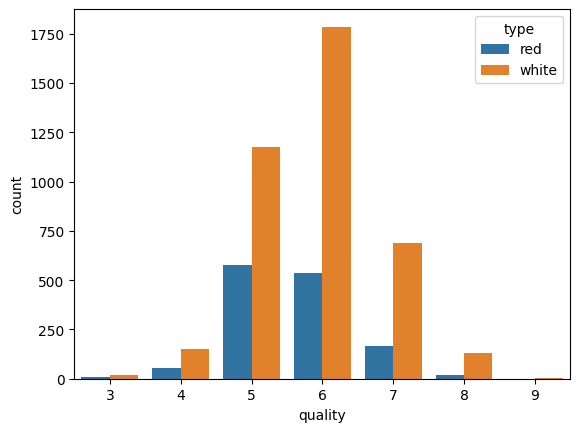

quality
3    0.005642
4    0.038744
5    0.329509
6    0.436336
7    0.160993
8    0.027835
9    0.000940
Name: proportion, dtype: float64


In [ ]:
df = pd.read_csv("../data/processed/winequality_clean.csv")

colunas_numericas = df.select_dtypes("number").columns

# Uma grade de 4 linhas x 3 colunas, um gráfico para cada variável
fig, eixos = plt.subplots(4, 3, figsize=(16, 14))

for eixo, coluna in zip(eixos.flatten(), colunas_numericas):
    sns.histplot(data=df, x=coluna, hue="type", bins=40, ax=eixo,
             stat="density", common_norm=False)
    eixo.set_title(coluna)

plt.tight_layout()
plt.show()